# 09B — Cross-domain movement matching

**Question.** Where does a prospect's *measured* Combine movement sit inside the *observed* NFL movement demands of his position — on dimensions that are physically the same on both sides?

**Five things kept apart** in every table, label and sentence:

| Thing | Where it comes from |
|---|---|
| measured Combine capability | the forty: maximal effort, from rest, with a repeat-attempt error |
| NFL movement demand | the distribution of what athletes of a position were observed to do (09A) |
| descriptive physical similarity | where the first sits inside the second — the only output of this notebook |
| observed NFL outcome | not an input here |
| validated ability to meet a demand | **not established** by any milestone of this project |

**Shared dimensions.** Band accelerations 2 → 4, 4 → 6 and 6 → 8 yd/s (the same first-crossing rule, `movement_demands.band_accel`, on both sides; 10 Hz on both sides) and the largest speed reached. A standing-start forty is not a rolling-start acceleration: that caveat is carried in the dictionary and in every reading.

**`coverage`.** The share of NFL episodes of a demand and position at or below the prospect's Combine value, with an interval from his repeat-attempt error. It is a position inside a distribution — not a probability, not a score, not a prediction.

**Abstention.** A demand without a forty analogue (braking, re-acceleration, redirection, maintenance, repeated changes) abstains for every prospect. A band crossing that was not recorded abstains. A thin NFL reference abstains.

**TCN-B is not used here.** Its encoder was trained on Combine sequences only; it cannot measure similarity to an NFL episode.

**Prerequisites (same `RUN_MODE`).** 01, 02, 04A, 07D, 09A. Optional: 08B.4 (evidence labels of the two reused atlas features).

In [1]:
RUN_MODE = 'full'             # 'smoke' | 'full'
SEED = 20261011
FORCE_REBUILD = False         # interface parity: every table of this notebook is recomputed on each run (seconds to a minute)
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
EXPERIMENT_VERSION = '09B.1'
EXAMPLE_ATHLETE = None        # nfl_id drawn in the alignment figures; None = the rule below (most supported comparisons, smallest id)
SHOW_TABLES = True

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.utils import utc_now
from nflbdb.research.advanced_movement import atlas as at
from nflbdb.research.advanced_movement import checkpoint as ck
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import intelligence_figures as ifg
from nflbdb.research.advanced_movement import intelligence_validation as iv
from nflbdb.research.advanced_movement import movement_demands as md
from nflbdb.research.advanced_movement import movement_information as mi
from nflbdb.research.advanced_movement import movement_matching as mm
from nflbdb.research.advanced_movement import nfl_outcomes as no
from nflbdb.research.advanced_movement import sequences as seq
from nflbdb.research.advanced_movement.artifacts import IntelligenceStore
from nflbdb.research.advanced_movement.scoring import scorecards as sc

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
store = IntelligenceStore(cfg, controls)
up, SC, FB = store.upstream, store.scoring, store.football
amc.seed_everything(controls.seed)
OC = no.OutcomeConfig().for_mode(controls)
DC = md.DemandConfig().for_mode(controls)
MC = mm.MatchingConfig(min_nfl_episodes=DC.min_episodes, min_nfl_athletes=DC.min_athletes, min_repeat=5 if controls.smoke else 20)
NB = {'01': '01_sequence_eda_and_alignment.ipynb', '02': '02_functional_pca_baseline.ipynb', '04A': '04a_feature_characteristic_atlas.ipynb',
      '07D': '07d_athletic_fingerprint_scorecard.ipynb', '09A': '09a_nfl_movement_demand_atlas.ipynb', '09B': '09b_cross_domain_movement_matching.ipynb'}

profile = SC.require(sc.PROFILE, NB['07D'])                         # pre-draft roster and official tests (READ ONLY)
frames = up.require(seq.SEQ_FRAMES, NB['01'])
windows = up.require(ck.WINDOWS, NB['02'])
attempt_values = store.atlas.require(at.ATTEMPT_VALUES, NB['04A'])
episodes = store.require(md.EPISODES, NB['09A'])
registry08 = FB.read(mi.REGISTRY) if FB.exists(mi.REGISTRY) else None
if registry08 is None:
    print('08B.4 evidence registry absent for this run mode: the two reused atlas features take the local screen of this notebook')
sc.assert_no_nfl_columns(profile, 'profile')
PROV = {'notebook': NB['09B'], 'experiment_version': EXPERIMENT_VERSION, 'run_mode': controls.run_mode, 'seed': controls.seed, 'matching_config': MC.params(),
        'demand_config': DC.params(), 'nfl_inputs_of_combine_tables': 'none'}
save = lambda df, c: store.write(df, c, '09B', PROV) if controls.save_tables else df
label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · {profile.height} Combine profiles · {windows.height} eligible forty attempts · {episodes.height:,} NFL demand episodes'))

**Run mode: `full`** (FULL) · 510 Combine profiles · 793 eligible forty attempts · 486,626 NFL demand episodes

## 1 · Synthetic checks

The Combine side calls the NFL-side band rule; unrecorded intervals abstain; coverage is exact on a known reference; unsupported demands, thin references and missing error estimates abstain; an NFL column in a Combine table is refused.

In [3]:
validation = iv.run_all(iv.CHECKS_MATCHING)
with pl.Config(fmt_str_lengths=220, tbl_rows=-1):
    display(validation)
iv.assert_all_passed(validation)

check,status,detail
str,str,str
"""shared_rule_on_both_domains""","""PASS""","""Combine band accelerations use the same first-crossing rule as NFL episodes; unrecorded intervals abstain"""
"""similarity_coverage_and_abstention""","""PASS""","""coverage is a position inside the NFL demand distribution; thin references, missing values and unsupported demands abstain"""


## 2 · Shared movement-feature dictionary

One row per dimension: its definition on each side, unit, sampling, smoothing, window rule — and whether the pair is comparable at all. Demands without a forty analogue are listed as **not comparable** with the reason.

*Assumption to keep in view:* both sides use the project's Savitzky–Golay kinematics; the Combine sequence frames come from notebook 01 and the NFL frames from the Milestone 05 primary filter. If their filter settings differ, band values of a few frames differ slightly — the repeat-attempt error of the Combine side does not include that.

In [4]:
smoothing = f'Savitzky–Golay (NFL: window {OC.primary_smoothing[0]} frames, order {OC.primary_smoothing[1]}; Combine: sequence frames of notebook 01)'
dictionary = save(mm.dictionary_table(DC, smoothing), mm.DICTIONARY)
with pl.Config(tbl_rows=-1, tbl_width_chars=280, fmt_str_lengths=140):
    display(dictionary.select('dimension', 'unit', 'combine_definition', 'nfl_definition', 'demands', 'comparable', 'caveat'))

13:08:23 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:09B] movement_shared_feature_dictionary: 9 rows → warehouse/gold/advanced_movement/intelligence_v1/movement_shared_feature_dictionary.parquet


dimension,unit,combine_definition,nfl_definition,demands,comparable,caveat
str,str,str,str,str,bool,str
"""acc_2_4""","""yd/s²""","""forty-yard dash: (4 − 2) / time between the first recorded crossings of 2 and 4 yd/s""","""accelerating episode: the same quantity between the first crossings INSIDE the episode""","""accel_low""",true,"""the forty is one maximal-effort transit from rest; an NFL episode is a context-driven, usually submaximal effort"""
"""acc_4_6""","""yd/s²""","""forty-yard dash: (6 − 4) / time between the first recorded crossings of 4 and 6 yd/s""","""accelerating episode: the same quantity between the first crossings INSIDE the episode""","""accel_low, accel_mid""",true,"""the forty is one maximal-effort transit from rest; an NFL episode is a context-driven, usually submaximal effort"""
"""acc_6_8""","""yd/s²""","""forty-yard dash: (8 − 6) / time between the first recorded crossings of 6 and 8 yd/s""","""accelerating episode: the same quantity between the first crossings INSIDE the episode""","""accel_mid, transition_high""",true,"""the forty is one maximal-effort transit from rest; an NFL episode is a context-driven, usually submaximal effort"""
"""top_speed""","""yd/s""","""95th percentile of tracked speed in the forty (atlas F2.forty.p95_speed)""","""largest speed of a sustained high-speed episode""","""sustained_high""",true,"""40 yards may end before an athlete's top speed; game speed is not a maximum"""
"""(speed_maintenance)""","""yd/s""","""not measured by the forty-yard dash""","""|tangential acceleration| < 1 yd/s² at ≥ 5 yd/s for ≥ 1 s""","""speed_maintenance""",false,"""none: forty recordings usually end at or before the speed peak (last-frame censoring)"""
"""(braking)""","""yd/s²""","""not measured by the forty-yard dash""","""a run with tangential acceleration ≤ −1 yd/s² for ≥ 0.4 s from ≥ 4 yd/s with a speed drop ≥ 2 yd/s""","""braking""",false,"""none: the forty contains no braking phase inside the timed run"""
"""(reaccel_after_brake)""","""yd/s²""","""not measured by the forty-yard dash""","""a run of frames with tangential acceleration ≥ 1 yd/s² lasting ≥ 0.5 s with a speed gain ≥ 1.5 yd/s, starting within 1 s after a braking epi…","""reaccel_after_brake""",false,"""none: the forty contains no braking, so no re-acceleration"""
"""(redirection)""","""deg""","""not measured by the forty-yard dash""","""|heading change| ≥ 45° at |yaw rate| ≥ 60 deg/s and speed ≥ 3 yd/s, every frame with a valid heading""","""redirection""",false,"""none: the forty is a straight run"""
"""(repeated_change)""","""episodes""","""not measured by the forty-yard dash""","""a player-play with ≥ 2 accelerating episodes and ≥ 1 braking episode""","""repeated_change""",false,"""none: a single maximal sprint has one acceleration phase"""


## 3 · Combine curve features and their local evidence

Per attempt: band accelerations and speed at 10 / 20 / 30 yd from the recorded frames, plus the two atlas features reused as executed (speed development 4 → 8 yd/s, tracked top speed). Per athlete: the mean of his attempts and a standard error from the pooled within-athlete variation of his position.

**Lightweight safeguard, local to these features.** Repeat-attempt ICC within position and in-sample R² on the official forty and 10-yard split. For the two atlas features the label is the executed 08B.4 registry status (residual repeatability, cross-fitted) — stronger evidence than this screen. `football_value` is `not established` on every row: repeatability is not football value.

13:08:24 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:09B] combine_curve_attempt_features: 6,344 rows → warehouse/gold/advanced_movement/intelligence_v1/combine_curve_attempt_features.parquet
13:08:24 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:09B] combine_curve_prospect_features: 4,080 rows → warehouse/gold/advanced_movement/intelligence_v1/combine_curve_prospect_features.parquet
13:08:24 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:09B] combine_curve_feature_evidence: 8 rows → warehouse/gold/advanced_movement/intelligence_v1/combine_curve_feature_evidence.parquet


feature,label,phase,n_athletes,n_repeat,icc_within_position,r2_official_times,evidence_status,evidence_source
str,str,str,i64,i64,f64,f64,str,str
"""acc_2_4""","""band acceleration 2 → 4 yd/s""","""early""",418,372,0.35183,0.077166,"""unstable""","""09B local screen (raw ICC and in-sample R²; weaker than the 08B.4 method)"""
"""acc_4_6""","""band acceleration 4 → 6 yd/s""","""middle""",418,375,0.485532,0.293608,"""unstable""","""09B local screen (raw ICC and in-sample R²; weaker than the 08B.4 method)"""
"""acc_6_8""","""band acceleration 6 → 8 yd/s""","""late""",418,375,0.606192,0.467373,"""moderately_repeatable_partly_beyond_stopwatch""","""09B local screen (raw ICC and in-sample R²; weaker than the 08B.4 method)"""
"""time_4_8""","""speed development 4 → 8 yd/s""","""middle""",418,375,0.822511,0.653568,"""repeatable_beyond_official""","""08B.4 scouting evidence registry (residual repeatability, cross-fitted)"""
"""top_speed""","""tracked top speed (p95)""","""late""",418,375,0.947951,0.868741,"""repeatable_beyond_official""","""08B.4 scouting evidence registry (residual repeatability, cross-fitted)"""
"""speed_10yd""","""speed at 10 yd""","""early""",418,375,0.732471,0.60794,"""moderately_repeatable_partly_beyond_stopwatch""","""09B local screen (raw ICC and in-sample R²; weaker than the 08B.4 method)"""
"""speed_20yd""","""speed at 20 yd""","""middle""",418,375,0.93482,0.898302,"""repeatable_mostly_stopwatch""","""09B local screen (raw ICC and in-sample R²; weaker than the 08B.4 method)"""
"""speed_30yd""","""speed at 30 yd""","""late""",418,375,0.951062,0.895067,"""repeatable_mostly_stopwatch""","""09B local screen (raw ICC and in-sample R²; weaker than the 08B.4 method)"""


feature,state,len
str,str,u32
"""acc_2_4""","""not_observed""",92
"""acc_2_4""","""supported""",418
"""acc_4_6""","""not_observed""",92
"""acc_4_6""","""supported""",418
"""acc_6_8""","""not_observed""",92
"""acc_6_8""","""supported""",418
"""speed_10yd""","""not_observed""",92
"""speed_10yd""","""supported""",418
"""speed_20yd""","""not_observed""",92


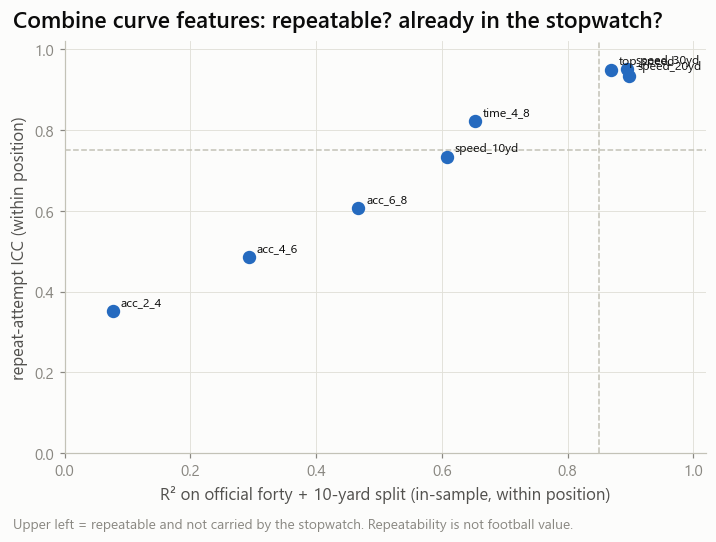

In [5]:
attempts = save(mm.attempt_table(frames, attempt_values, windows, MC), mm.ATTEMPTS)
prospect, evidence = mm.prospect_tables(attempts, profile, MC, registry08)
mm.assert_pre_draft(prospect, 'prospect curve features')
prospect, evidence = save(prospect, mm.PROSPECT), save(evidence, mm.EVIDENCE)
with pl.Config(tbl_rows=-1, tbl_width_chars=260, fmt_str_lengths=90):
    display(evidence.select('feature', 'label', 'phase', 'n_athletes', 'n_repeat', 'icc_within_position', 'r2_official_times', 'evidence_status', 'evidence_source'))
    display(prospect.group_by('feature', 'state').len().sort('feature', 'state'))
store.show(ifg.fig_feature_evidence(evidence, MC.icc_reference, MC.redundancy_reference), 'AM09B_01_curve_feature_evidence', {'evidence': evidence}, publication=True,
           source='combine_curve_feature_evidence', n=f'{int(evidence["n_repeat"].max() or 0)} athletes with a repeat (largest)')

## 4 · Prospect-to-demand similarity

One row per prospect × demand × shared dimension, with the NFL reference of **his position**, the coverage, its interval and a robust standardized distance — or an abstention state with its reason. The matrix summarises the supported dimensions of each demand; every row carries the reading *descriptive physical similarity — not a prediction*.

13:08:28 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:09B] movement_similarity: 5,610 rows → warehouse/gold/advanced_movement/intelligence_v1/movement_similarity.parquet
13:08:30 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:09B] movement_similarity_matrix: 4,590 rows → warehouse/gold/advanced_movement/intelligence_v1/movement_similarity_matrix.parquet
13:08:30 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:09B] movement_matching_summary: 30 rows → warehouse/gold/advanced_movement/intelligence_v1/movement_matching_summary.parquet


demand_id,dimension,state,len
str,str,str,u32
"""accel_low""","""acc_2_4""","""abstain_not_recorded""",92
"""accel_low""","""acc_2_4""","""supported""",418
"""accel_low""","""acc_4_6""","""abstain_not_recorded""",92
"""accel_low""","""acc_4_6""","""supported""",418
"""accel_mid""","""acc_4_6""","""abstain_not_recorded""",92
"""accel_mid""","""acc_4_6""","""supported""",418
"""accel_mid""","""acc_6_8""","""abstain_not_recorded""",92
"""accel_mid""","""acc_6_8""","""abstain_thin_nfl_reference""",129
"""accel_mid""","""acc_6_8""","""supported""",289


position_group,demand_id,dimension,n_prospects,n_abstain,median_coverage,q10_coverage,q90_coverage,median_interval_width,share_wide_interval,share_interval_spans_50,n_two_attempts,median_attempt_shift,spearman_with_forty
str,str,str,i64,i64,f64,f64,f64,f64,f64,f64,i64,f64,f64
"""DB""","""accel_low""","""acc_2_4""",102,20,93.778613,82.586732,97.916325,23.050359,0.431373,0.098039,93,3.728598,-0.108036
"""DB""","""accel_low""","""acc_4_6""",102,20,99.458657,97.160959,99.903761,2.955329,0.0,0.0,93,0.681691,-0.293129
"""DB""","""accel_mid""","""acc_4_6""",102,20,99.948927,99.259448,100.0,0.81716,0.0,0.0,93,0.153218,-0.318137
"""DB""","""accel_mid""","""acc_6_8""",102,20,100.0,99.389313,100.0,0.610687,0.019608,0.0,93,0.152672,-0.590232
"""DB""","""sustained_high""","""top_speed""",102,20,99.933584,99.822891,100.0,0.066416,0.0,0.0,93,0.0,-0.779386
"""DB""","""transition_high""","""acc_6_8""",102,20,99.492386,99.492386,99.492386,0.0,0.009804,0.0,93,0.0,-0.164532
"""DL""","""accel_low""","""acc_2_4""",93,25,91.841668,76.27839,98.799416,19.887193,0.290323,0.021505,84,4.902553,-0.414199
"""DL""","""accel_low""","""acc_4_6""",93,25,98.568951,90.693842,99.956635,3.946227,0.053763,0.0,84,0.910668,-0.768533
"""DL""","""accel_mid""","""acc_4_6""",93,25,99.404762,94.543651,100.0,1.388889,0.021505,0.0,84,0.446429,-0.757661


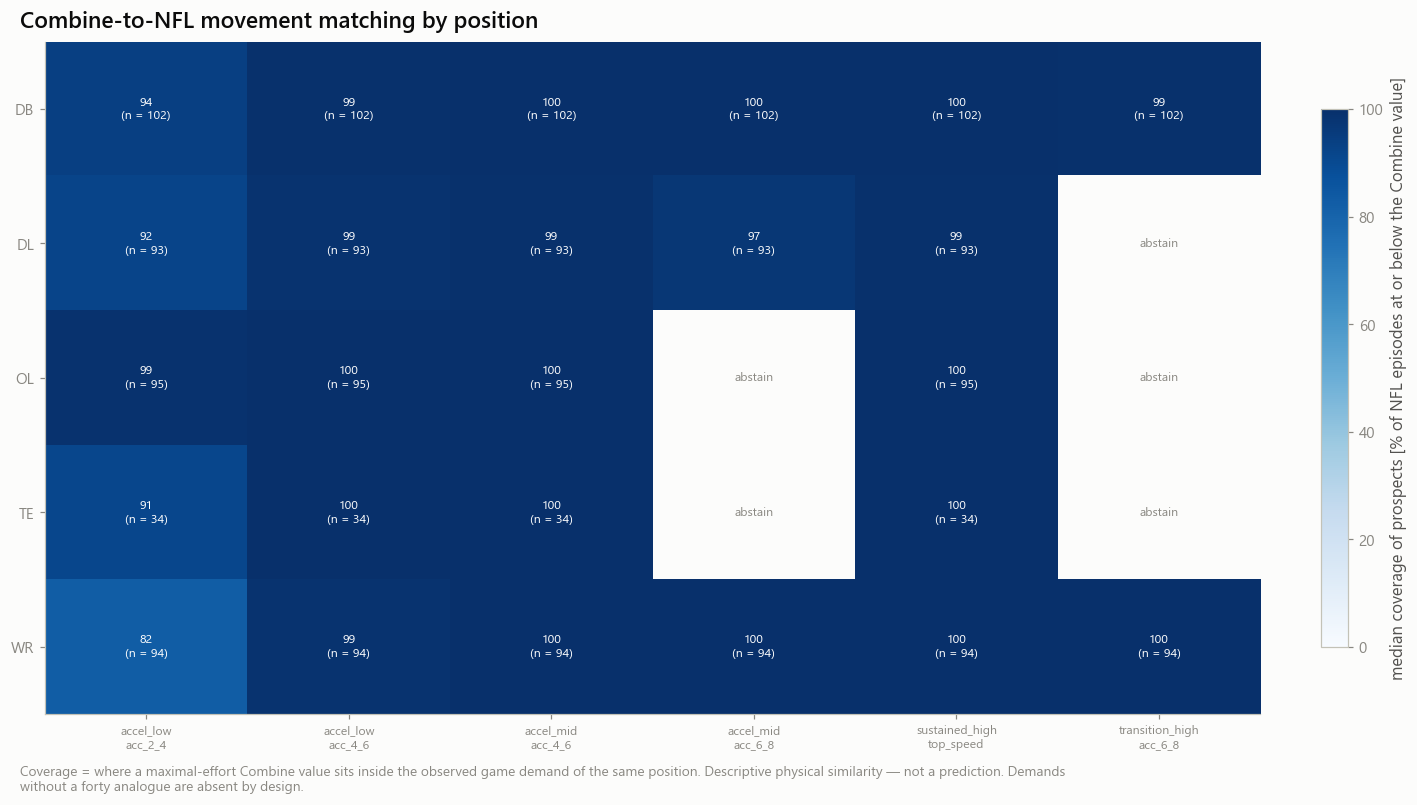

In [6]:
similarity = save(mm.similarity_table(prospect, episodes, DC, MC), mm.SIMILARITY)
matrix = save(mm.matrix_table(similarity), mm.MATRIX)
summary = save(mm.summary_table(similarity, attempts, episodes, profile, DC, MC), mm.DIM_SUMMARY)
with pl.Config(tbl_rows=-1, tbl_width_chars=240):
    display(similarity.group_by('demand_id', 'dimension', 'state').len().sort('demand_id', 'dimension', 'state'))
    if SHOW_TABLES:
        display(summary)
store.show(ifg.fig_similarity_heatmap(summary), 'AM09B_02_similarity_heatmap', {'summary': summary}, publication=True, source='movement_matching_summary',
           n=f'{similarity.filter(pl.col("state") == "supported")["nfl_id"].n_unique()} prospects with a supported comparison')

## 5 · Does matching reveal useful patterns?

Read from the summary table above, per position × demand × dimension:

- **Position differences** — `median_coverage` and its 10th–90th range.
- **Stability across Combine attempts** — `median_attempt_shift`: how far coverage moves between an athlete's two attempts.
- **Effect of measurement uncertainty** — `share_interval_spans_50`: prospects whose interval contains the NFL median, i.e. for whom measurement error alone decides the side.
- **Is this already in the stopwatch?** — `spearman_with_forty`: near −1 means the official forty already orders prospects the same way.

The figures below draw one prospect chosen by a rule fixed here (the most supported comparisons, smallest id) — or the athlete set in `EXAMPLE_ATHLETE`.

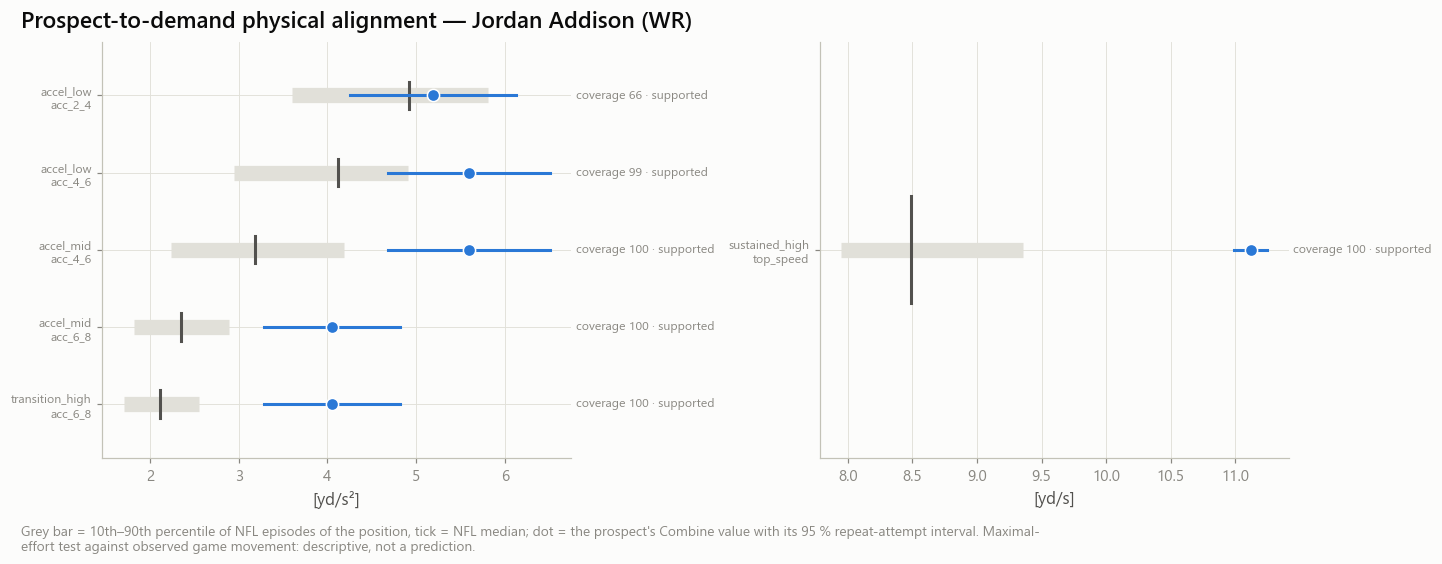

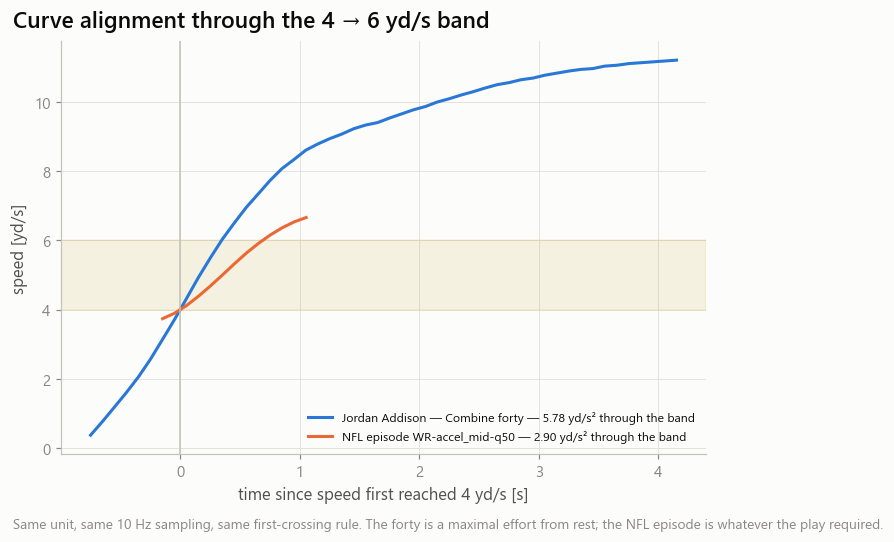

In [7]:
ok = similarity.filter(pl.col('state') == 'supported')
if EXAMPLE_ATHLETE is None and ok.height:
    EXAMPLE_ATHLETE = ok.group_by('nfl_id').len().sort('len', 'nfl_id', descending=[True, False])['nfl_id'][0]
if EXAMPLE_ATHLETE is not None:
    who = profile.filter(pl.col('nfl_id') == EXAMPLE_ATHLETE).row(0, named=True)
    name = who['display_name'] or str(EXAMPLE_ATHLETE)
    mine = similarity.filter((pl.col('nfl_id') == EXAMPLE_ATHLETE) & (pl.col('dimension') != '—'))
    store.show(ifg.fig_alignment(mine.to_dicts(), name + ' (' + who['position_group'] + ')'), f'AM09B_03_prospect_demand_alignment_{EXAMPLE_ATHLETE}', {'similarity': mine},
               publication=True, source='movement_similarity', n='one prospect; NFL reference sizes in the table')
    examples = store.read(md.EXAMPLES) if store.exists(md.EXAMPLES) else None
    seqs = windows.filter(pl.col('nfl_id') == EXAMPLE_ATHLETE).sort('attempt_order')['seq_id'].to_list()[:1]
    ex = None if examples is None else examples.filter((pl.col('position_group') == who['position_group']) & (pl.col('demand_id') == 'accel_mid') & pl.col('in_episode'))
    if seqs and ex is not None and ex.height:
        one = ex.filter(pl.col('example_id') == ex['example_id'][0]).sort('frame')
        combine = ifg.traces(frames, seqs, 't_rel', 'speed')[0]
        lo, hi = md.BANDS[1]
        store.show(ifg.fig_curve_alignment(combine, (one['t_s'].to_numpy(), one['speed'].to_numpy()), lo, hi, (name + ' — Combine forty', 'NFL episode ' + one['example_id'][0])),
                   'AM09B_04_curve_alignment_example', {'nfl_episode': one}, publication=True, source='sequence_frames + nfl_movement_demand_examples', n='one attempt and one real play')
    else:
        print('curve-alignment example skipped: no example episode (09A with BUILD_EXAMPLES = True) or no attempt')
else:
    print('no supported comparison: alignment figures skipped')

## 6 · Reading and output contract

| Output | Grain |
|---|---|
| `movement_shared_feature_dictionary` | dimension |
| `combine_curve_attempt_features` | sequence × feature |
| `combine_curve_prospect_features` | athlete × feature |
| `combine_curve_feature_evidence` | feature |
| `movement_similarity` | athlete × demand × dimension |
| `movement_similarity_matrix` | athlete × demand |
| `movement_matching_summary` | position × demand × dimension |

**Limits.** A maximal-effort test against observed, usually submaximal game movement. Coverage near 100 for most prospects of a position would mean the forty value exceeds what games usually ask — it would not mean the demand is easy to meet in pads, in traffic, on the fifth play of a drive. No NFL outcome is used and none is predicted.

In [8]:
reading = mm.conclusions(evidence, summary, matrix)
display(Markdown('\n'.join('- ' + s for s in reading)))
if controls.save_tables:
    store.write_json('movement_matching_manifest', {'experiment_version': EXPERIMENT_VERSION, 'finished_at': utc_now(), 'n_prospects': int(prospect['nfl_id'].n_unique()),
                                                    'n_supported_rows': ok.height, 'states': {r[0]: r[1] for r in similarity.group_by('state').len().iter_rows()},
                                                    'example_athlete': EXAMPLE_ATHLETE, 'reading': reading, 'provenance': PROV})
print('Send back: the checks table, the evidence table, the state counts, the summary table, figures AM09B_01–03, and the reading above.')
print('Next: 09c_stopwatch_twins_discovery.ipynb')

- band acceleration 2 → 4 yd/s: ICC 0.35 (372 athletes with a repeat), R² on official times 0.08 → unstable.
- band acceleration 4 → 6 yd/s: ICC 0.49 (375 athletes with a repeat), R² on official times 0.29 → unstable.
- band acceleration 6 → 8 yd/s: ICC 0.61 (375 athletes with a repeat), R² on official times 0.47 → moderately_repeatable_partly_beyond_stopwatch.
- speed development 4 → 8 yd/s: ICC 0.82 (375 athletes with a repeat), R² on official times 0.65 → repeatable_beyond_official.
- tracked top speed (p95): ICC 0.95 (375 athletes with a repeat), R² on official times 0.87 → repeatable_beyond_official.
- speed at 10 yd: ICC 0.73 (375 athletes with a repeat), R² on official times 0.61 → moderately_repeatable_partly_beyond_stopwatch.
- speed at 20 yd: ICC 0.93 (375 athletes with a repeat), R² on official times 0.90 → repeatable_mostly_stopwatch.
- speed at 30 yd: ICC 0.95 (375 athletes with a repeat), R² on official times 0.90 → repeatable_mostly_stopwatch.
- DB · accel_low · acc_2_4: 102 prospects, median coverage 94, interval spans the NFL median for 10 %, attempt shift 4 points, ρ with the forty -0.11.
- DB · accel_low · acc_4_6: 102 prospects, median coverage 99, interval spans the NFL median for 0 %, attempt shift 1 points, ρ with the forty -0.29.
- DB · accel_mid · acc_4_6: 102 prospects, median coverage 100, interval spans the NFL median for 0 %, attempt shift 0 points, ρ with the forty -0.32.
- DB · accel_mid · acc_6_8: 102 prospects, median coverage 100, interval spans the NFL median for 0 %, attempt shift 0 points, ρ with the forty -0.59.
- DB · sustained_high · top_speed: 102 prospects, median coverage 100, interval spans the NFL median for 0 %, attempt shift 0 points, ρ with the forty -0.78.
- DB · transition_high · acc_6_8: 102 prospects, median coverage 99, interval spans the NFL median for 0 %, attempt shift 0 points, ρ with the forty -0.16.
- DL · accel_low · acc_2_4: 93 prospects, median coverage 92, interval spans the NFL median for 2 %, attempt shift 5 points, ρ with the forty -0.41.
- DL · accel_low · acc_4_6: 93 prospects, median coverage 99, interval spans the NFL median for 0 %, attempt shift 1 points, ρ with the forty -0.77.
- DL · accel_mid · acc_4_6: 93 prospects, median coverage 99, interval spans the NFL median for 0 %, attempt shift 0 points, ρ with the forty -0.76.
- DL · accel_mid · acc_6_8: 93 prospects, median coverage 97, interval spans the NFL median for 25 %, attempt shift 3 points, ρ with the forty -0.92.
- DL · sustained_high · top_speed: 93 prospects, median coverage 99, interval spans the NFL median for 0 %, attempt shift 0 points, ρ with the forty -0.97.
- OL · accel_low · acc_2_4: 95 prospects, median coverage 99, interval spans the NFL median for 1 %, attempt shift 1 points, ρ with the forty -0.44.
- OL · accel_low · acc_4_6: 95 prospects, median coverage 100, interval spans the NFL median for 2 %, attempt shift 0 points, ρ with the forty -0.63.
- OL · accel_mid · acc_4_6: 95 prospects, median coverage 100, interval spans the NFL median for 0 %, attempt shift 0 points, ρ with the forty -0.10.
- OL · sustained_high · top_speed: 95 prospects, median coverage 100, interval spans the NFL median for 0 %, attempt shift 0 points, ρ with the forty -0.41.
- TE · accel_low · acc_2_4: 34 prospects, median coverage 91, interval spans the NFL median for 18 %, attempt shift 9 points, ρ with the forty -0.43.
- TE · accel_low · acc_4_6: 34 prospects, median coverage 100, interval spans the NFL median for 0 %, attempt shift 0 points, ρ with the forty -0.75.
- TE · accel_mid · acc_4_6: 34 prospects, median coverage 100, interval spans the NFL median for 0 %, attempt shift 0 points, ρ with the forty -0.72.
- TE · sustained_high · top_speed: 34 prospects, median coverage 100, interval spans the NFL median for 0 %, attempt shift 0 points, ρ with the forty n/a.
- WR · accel_low · acc_2_4: 94 prospects, median coverage 82, interval spans the NFL median for 76 %, attempt shift 10 points, ρ with the forty -0.05.
- WR · accel_low · acc_4_6: 94 prospects, median coverage 99, interval spans the NFL median for 22 %, attempt shift 1 points, ρ with the forty -0.17.
- WR · accel_mid · acc_4_6: 94 prospects, median coverage 100, interval spans the NFL median for 0 %, attempt shift 0 points, ρ with the forty -0.15.
- WR · accel_mid · acc_6_8: 94 prospects, median coverage 100, interval spans the NFL median for 1 %, attempt shift 0 points, ρ with the forty -0.36.
- WR · sustained_high · top_speed: 94 prospects, median coverage 100, interval spans the NFL median for 0 %, attempt shift 0 points, ρ with the forty -0.50.
- WR · transition_high · acc_6_8: 94 prospects, median coverage 100, interval spans the NFL median for 0 %, attempt shift 0 points, ρ with the forty -0.21.
- Demands the forty cannot describe (abstained for every prospect): braking, reaccel_after_brake, redirection, repeated_change, speed_maintenance.

Send back: the checks table, the evidence table, the state counts, the summary table, figures AM09B_01–03, and the reading above.
Next: 09c_stopwatch_twins_discovery.ipynb
